# 1.0 - Data Ingestion & Exploratory Data Analysis
**Week 1** | Axlero DA Internship - Project 1: Customer Segmentation & Churn

**Goal:** pull transactions from PostgreSQL, audit quality, clean *programmatically* (target: drop < 5 % of rows), understand distributions and sales trends.

**Business question:** who are our customers and what does the raw data look like before we trust it?

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src import config, features as F
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
def save(name):
    config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    plt.savefig(config.FIGURES_DIR / name, dpi=140, bbox_inches="tight")


## 1. Load from PostgreSQL
Raw CSVs were loaded into `transactions_raw` / `customers` (`src/dataset.py`). The view `v_transactions_clean` removes exact duplicate rows in SQL (`sql/02_clean_view.sql`).

In [2]:
raw = F.load_clean_view()
customers = pd.read_csv(config.DATA_RAW / 'customers.csv', parse_dates=['signup_date'])
print(raw.shape, '| rows in DB table:', raw.attrs['rows_in_db'])
raw.head()

(64515, 8) | rows in DB table: 64837


,order_id,customer_id,order_date,category,unit_price,quantity,channel,discount_pct
0,506163,10964,2024-01-01 17:40:00,Beauty,19.31,3.0,web,0.1
1,506163,10964,2024-01-01 17:40:00,Beauty,27.15,1.0,mobile_app,0.0
2,506163,10964,2024-01-01 17:40:00,Beauty,42.86,NaN,mobile_app,0.0
3,525506,13959,2024-01-03 15:22:00,Electronics,67.24,1.0,mobile_app,0.0
4,507175,11151,2024-01-04 09:14:00,Apparel,41.35,-3.0,web,0.0


## 2. Data-quality audit

In [3]:
audit = pd.DataFrame({'missing': raw.isna().sum(), 'pct_missing': (raw.isna().mean()*100).round(2)})
print(audit[audit.missing > 0])
print('\nNegative quantities (returns):', int((raw.quantity < 0).sum()))
print(raw[['unit_price','quantity','discount_pct']].describe().round(2))

            missing  pct_missing
unit_price     1290          2.0
quantity        967          1.5
channel        1290          2.0

Negative quantities (returns): 634
       unit_price  quantity  discount_pct
count    63225.00  63548.00      64515.00
mean       128.85      1.27          0.03
std        357.07      0.69          0.06
min          7.82     -3.00          0.00
25%         54.30      1.00          0.00
50%         89.94      1.00          0.00
75%        143.49      1.00          0.00
max      23311.92      3.00          0.20


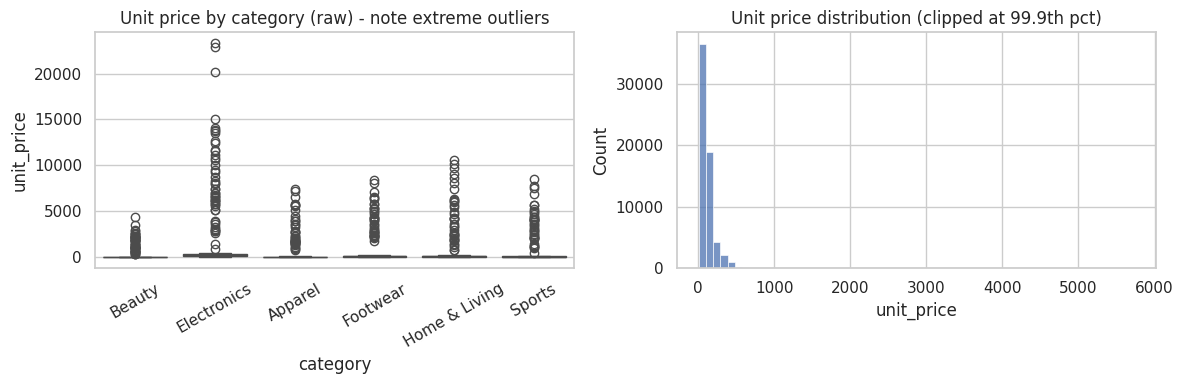

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=raw, x='category', y='unit_price', ax=ax[0]); ax[0].set_title('Unit price by category (raw) - note extreme outliers'); ax[0].tick_params(axis='x', rotation=30)
sns.histplot(raw.unit_price.dropna().clip(upper=raw.unit_price.quantile(.999)), bins=60, ax=ax[1]); ax[1].set_title('Unit price distribution (clipped at 99.9th pct)')
plt.tight_layout(); save('01_price_outliers_raw.png'); plt.show()

## 3. Programmatic cleaning (`src.features.clean_transactions`)
| Issue | Treatment | Why |
|---|---|---|
| exact duplicate rows | removed (SQL `DISTINCT`) | true duplicates inflate frequency |
| missing unit price | category median | robust to outliers, keeps the row |
| missing quantity | 1 (mode) | most common basket quantity |
| missing channel | `unknown` | keeps missingness as information |
| price outliers | winsorised at per-category 99th pct | cap, don't drop |
| negative quantity | flagged `is_return`, excluded from revenue | returns are not purchases |

In [5]:
tx, audit = F.clean_transactions(raw)
for k, v in audit.items(): print(f'{k:28s}{v}')
print('\nData-integrity target (< 5% dropped):', 'PASS' if audit['pct_rows_dropped'] < 5 else 'FAIL')

rows_raw                    64837
exact_duplicates_removed    322
missing_unit_price          1290
missing_quantity            967
missing_channel             1290
price_outliers_capped       648
rows_clean                  64515
pct_rows_dropped            0.497

Data-integrity target (< 5% dropped): PASS


In [6]:
tx.to_csv(config.DATA_INTERIM / 'transactions_clean.csv', index=False)
F.extract_user_level().to_csv(config.DATA_INTERIM / 'user_level_extract.csv', index=False)
import json; (config.DATA_INTERIM / 'cleaning_audit.json').write_text(json.dumps(audit, indent=2))
user_level = pd.read_csv(config.DATA_INTERIM / 'user_level_extract.csv')
print(user_level.shape); user_level.head()

(5000, 11)


,customer_id,signup_date,city,acquisition_channel,n_orders,first_order_date,last_order_date,total_spend,avg_order_value,avg_lines_per_order,n_returns
0,10001,2024-07-22,Mumbai,referral,1,2024-08-09 20:33:00,2024-08-09 20:33:00,21.070,21.070000,1.000000,0
1,10002,2024-05-10,Hyderabad,referral,1,2024-05-23 20:12:00,2024-05-23 20:12:00,297.954,297.954000,1.000000,0
2,10003,2024-11-08,Hyderabad,organic,1,2024-11-22 22:56:00,2024-11-22 22:56:00,441.570,441.570000,3.000000,0
3,10004,2025-02-01,Pune,organic,1,2025-05-26 20:47:00,2025-05-26 20:47:00,105.370,105.370000,2.000000,0
4,10005,2024-06-05,Chennai,paid_social,31,2024-07-03 21:01:00,2025-10-29 21:18:00,7369.029,237.710613,1.935484,2


## 4. Sales trends

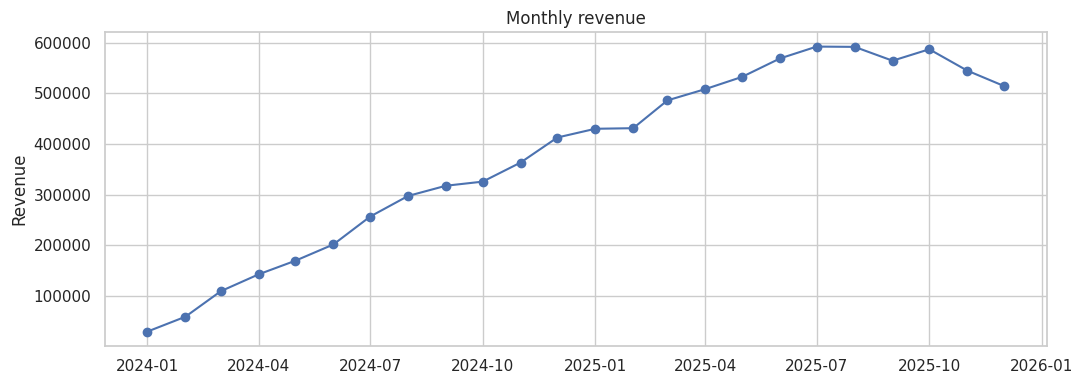

In [7]:
monthly = tx.set_index('order_date').resample('MS').agg(revenue=('line_value','sum'), orders=('order_id','nunique'))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly.revenue, marker='o'); ax.set_title('Monthly revenue'); ax.set_ylabel('Revenue')
plt.tight_layout(); save('02_monthly_revenue.png'); plt.show()

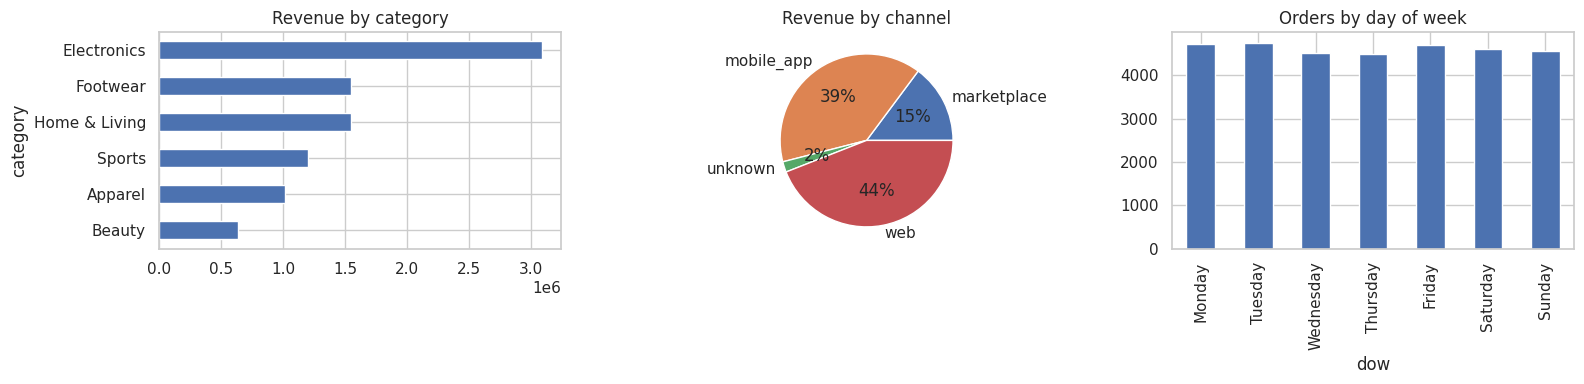

In [8]:
tx['dow'] = tx.order_date.dt.day_name(); tx['hour'] = tx.order_date.dt.hour
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
tx.groupby('category').line_value.sum().sort_values().plot.barh(ax=ax[0], title='Revenue by category')
tx.groupby('channel').line_value.sum().plot.pie(ax=ax[1], autopct='%1.0f%%', title='Revenue by channel', ylabel='')
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
tx.groupby('dow').order_id.nunique().reindex(order).plot.bar(ax=ax[2], title='Orders by day of week')
plt.tight_layout(); save('03_category_channel_dow.png'); plt.show()

## 5. Customer-level distributions
Order frequency and spend are **heavily right-skewed** - a few customers drive most revenue. This motivates the `log1p` transform before clustering (notebook 2.0).

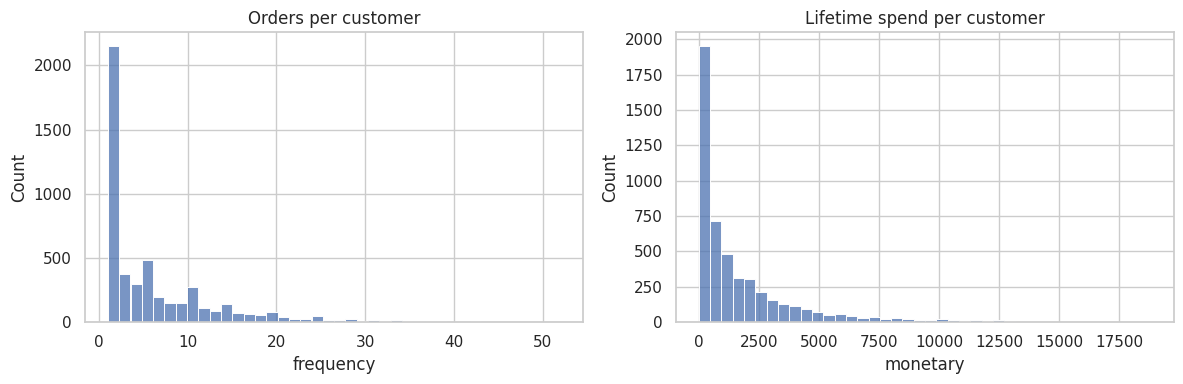

Top 20% of customers generate 65% of revenue


In [9]:
orders = tx.groupby(['customer_id','order_id']).line_value.sum().reset_index()
cust = orders.groupby('customer_id').agg(frequency=('order_id','nunique'), monetary=('line_value','sum'))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(cust.frequency, bins=40, ax=ax[0]); ax[0].set_title('Orders per customer')
sns.histplot(cust.monetary, bins=40, ax=ax[1]); ax[1].set_title('Lifetime spend per customer')
plt.tight_layout(); save('04_customer_skew.png'); plt.show()
top20 = cust.monetary.sort_values(ascending=False).head(int(len(cust)*.2)).sum() / cust.monetary.sum()
print(f'Top 20% of customers generate {top20:.0%} of revenue')

## Key findings
* Cleaning dropped well under the 5 % ceiling - missing values were imputed and outliers capped, not deleted.
* Revenue is highly concentrated in a small share of customers (Pareto), so one-size-fits-all marketing is wasteful.
* Skewed F and M need log-scaling; returns must be excluded from monetary value.

**Next:** RFM features and K-Means segmentation (2.0).